# Map flux

 ### 1) Read L(nu;z).
 
 ### 2) Find closest freq to nu_target and collapse L(nu;z) --> L(z).
 
 ### 3) Build sky map (x,y) in mas units.
 
 ### 4) Evaluate L(x,y) from L(z), assuming optically thin jet and homogeneous distribution of luminosity over height slices. 
 
 ### 5) Convert luminosity to flux and mirror in x.
 
 ### 6) Convolute with Gaussian elliptical beam.
 
 ### 7) Plotting.

### Import modules

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Colormap

### User parameters

In [2]:
incl = 30.0 * np.pi / 180.0
Nx = 50 # = Ns ?
nu_target_GHz = 43
f_Ny = 0.5 # Nyquist frequency
sigma_x = 0.01 # Beam resolution in [mas] (--> 0.31 mas)
sigma_y = 0.02 # Beam resolution in [mas] (--> 0.31 mas) 
#co = sqrt(8.d0*log(2.d0))       ! difference between sigma and theta!, theta = sigma*co

### Define some constants

In [3]:
h = 6.6260755e-27
eV = 1.602176e-12
kpc = 3.0856e21
distance = 16.4e3
convert = 206265.e3/(distance*kpc) # imagen a tamano angular (mas)
flux = 1.e26*(h/eV)/(4.0*np.pi*(distance*kpc)**2) # L[erg/s/erg] -> F[mJy]

### Define some useful functions

In [4]:
def read_SEDsyn_cuts( filename='SEDsyn_cuts_ord.dat'):
    Ns = 256 # TODO: Leer de archivo
    nIn = 150 # TODO: Leer de archivo
    fname = filename
    #fname format: Esy, Lsy*Esy, Labssy, l
    data = np.loadtxt(fname, usecols=(0,2))
    Esy = np.zeros((nIn))
    Esy_test = np.zeros((nIn))
    Lsy = np.zeros((nIn,Ns))
    j=0
    for l in range(0,Ns): #do l = 1, Ns 
        j = l*nIn
        for i in range(0,nIn): #do i = 1, nIn
            Esy[i] = data[i,0]
            Lsy[i,l] = data[j+i,1]/Esy[i]
            if l == 0:
                Esy_test[i] = Esy[i]
            if Esy[i] != Esy_test[i]:
                print("ERROR")
                exit()

    return Esy, Lsy

In [5]:
def get_Lsyn_z( Esy, Lsy, nu_target):
    E_nu_target = h * nu_target * 1.e9 / eV
    # Step through energies:
    log_Eint = np.log10(Esy[1]/Esy[0])
    i_nu_target = int(np.log10( E_nu_target/Esy[0]) /log_Eint)
    return Lsy[i_nu_target, :]

In [6]:
def get_z_rz( filename='quant_FF.dat'):
    fname = filename
    data = np.loadtxt(fname, usecols=(0,2))
    return data[:,0], data[:,1]

In [7]:
def make_F_map( nu, sigma_x, sigma_y, Nx ):
    Esy, Lsy = read_SEDsyn_cuts()
    L_z = get_Lsyn_z( Esy, Lsy, nu )
    z, r_z = get_z_rz()
    y_map = z * np.sin( incl) * convert
    x = np.linspace( 0, r_z[-1], Nx) * convert
    dx = x[1] - x[0]
    
    r_z_proj = r_z * convert
    L_map = np.ones(( len( x), len( y_map))) * 0
    for j in range( len( y_map)):
        for i in range( len( x)):
            if x[ i] < r_z_proj[ j]:
                L_map[i,j] = 2.0 * L_z[ j] * np.sqrt( r_z_proj[ j]**2.0 - x[ i]**2.0) / (np.pi * r_z_proj[ j]**2.0)
                L_map[i,j] = L_map[i,j] * dx
        # Correction factor for better conservation of luminosity
        temp = np.sum( L_map[:,j])
        L_map[:,j] = L_map[:,j] * 0.5*L_z[j] / temp
        
    x_map = np.ones(( 2*len(x)))
    F_map = np.ones(( len(x_map), len(y_map)))
    for i in range( len(L_map[:,0])):
        x_map[i+Nx] = x[i]
        x_map[Nx-i-1] = -x[i]
        for j in range( len(L_map[0,:])):
            F_map[i+Nx,j] = L_map[i,j]*flux
            F_map[Nx-i-1,j] = L_map[i,j]*flux
            
    return x_map, y_map, F_map

In [8]:
def make_spix_map( x_c, y_c, nu1, F_map1, nu2, F_map2):
    spix_map = np.zeros((len(x_c), len(y_c)))
    log_nu2nu1 = np.log(nu2/nu1)

    for i in range(len(x_c)):
        for j in range(len(y_c)):
            if ( F_map2[i,j] > 1e-3 & F_map1[i,j] > 2e-2 ): # Define according to rms of maps! (e.g. at least 20 uJy)
                   spix_map[i,j] = np.log( F_map2[i,j]/F_map1[i,j] ) / log_nu2nu1
    return spix_map

### 1) Read L(nu;z).

In [9]:
Esy, Lsy = read_SEDsyn_cuts()

### 2) Find closest freq to nu_target and collapse L(nu;z) --> L(z).

In [10]:
L_z = get_Lsyn_z( Esy, Lsy, nu_target_GHz)

 ### 3) Build sky map (x,y) in mas units.

In [11]:
z, r_z = get_z_rz()

In [12]:
y_map = z * np.sin( incl) * convert

In [13]:
x = np.linspace( 0, r_z[-1], Nx) * convert
dx = x[1] - x[0]

 ### 4) Evaluate L(x,y) from L(z), assuming optically thin jet and homogeneous distribution of luminosity over height slices. 

In [14]:
r_z_proj = r_z * convert
L_map = np.ones(( len( x), len( y_map))) * 0
for j in range( len( y_map)):
    for i in range( len( x)):
        if x[ i] < r_z_proj[ j]:
            L_map[i,j] = 2.0 * L_z[ j] * np.sqrt( r_z_proj[ j]**2.0 - x[ i]**2.0) / (np.pi * r_z_proj[ j]**2.0)
            L_map[i,j] = L_map[i,j] * dx
    # Correction factor for better conservation of luminosity
    temp = np.sum( L_map[:,j])
    L_map[:,j] = L_map[:,j] * 0.5*L_z[j] / temp

 ### 5) Convert luminosity to flux and mirror in x.

In [15]:
x_map = np.ones(( 2*len(x)))
F_map = np.ones(( len(x_map), len(y_map)))
for i in range( len(L_map[:,0])):
    x_map[i+Nx] = x[i]
    x_map[Nx-i-1] = -x[i]
    for j in range( len(L_map[0,:])):
        F_map[i+Nx,j] = L_map[i,j]*flux
        F_map[Nx-i-1,j] = L_map[i,j]*flux

###  6) Convolve with Gaussian elliptical beam.

In [16]:
# The number of points in the convolved map depends on the beam size and the size of the original map.

ancho_x = 2.0*x_map[-1] * 1.2 
ancho_y = y_map[-1] * 1.2

Dx_c = f_Ny*sigma_x
Dy_c = f_Ny*sigma_y

Nx_c = int(ancho_x/Dx_c)
Ny_c = int(ancho_y/Dy_c)

x_c = np.linspace( x_map[1]*1.1, x_map[-1]*1.1, Nx_c)
y_c = np.linspace( -2*sigma_y, y_map[-1]*1.1, Ny_c)

print('Dimension of the convolution grid: ' + str(Nx_c) + 'x' + str(Ny_c))

Dimension of the convolution grid: 17x21


In [17]:
F_map_c = np.ones((Nx_c, Ny_c))

w_x = 2.0*sigma_x**2 # weight for x distance
w_y = 2.0*sigma_y**2 # weight for y distance

for i in range(Nx_c):
    print(i)
    for j in range(Ny_c):    
        sum = 0.0
        for l_x in range(len(x_map)):    
            d_x2 = ( x_map[l_x] - x_c[i] )**2
            if d_x2 < 4.0 * w_x:
                for l_y in range(len(y_map)): 
                    d_y2 = ( y_map[l_y] - y_c[j] )**2
                    weight = d_x2/w_x + d_y2/w_y
                    D_F = 0.0
                    if (weight < 4.0): # flux drops < 1e-3 farther from there, no need to sum  
                        atenua = np.exp( -weight )
                        D_F = F_map[l_x,l_y] * atenua
                    #print(suma, D_F)
                    sum = sum + D_F
        F_map_c[i,j] = sum

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16


In [18]:
S_pre = np.sum(F_map)
print('Pre-conv: S(GHz) = ' + str(S_pre) + ' mJy')

# Gaussian beam -> exp(...)/(sigma*sqrt(2*pi)), both in x and y
A_beam = 2 * np.pi * sigma_x * sigma_y     # = Gaussian normalization factor 
A_cell = Dx_c * Dy_c              # cell sample size
mJy_beam = A_cell/A_beam          # Transform mJy/beam -> mJy (for checks)
S_post = np.sum(F_map_c) * mJy_beam
print('Post-conv: S(GHz) = ' + str(S_post) + ' mJy')
print('post/pre = ' + str(S_post/S_pre) )

Pre-conv: S(GHz) = 0.0024053189812199465 mJy
Post-conv: S(GHz) = 0.0019572423384003165 mJy
post/pre = 0.8137142531539117


### 7) Spix map

### 8) Plotting

In [19]:
nice_fonts = {
        # Use LaTeX to write all text
        "text.usetex": True,
        "font.family": 'serif',
        # Use 10pt font in plots, to match 10pt font in document
        "axes.labelsize": 16,
        "font.size": 16,
        "axes.linewidth":1,
        "axes.titlesize":20,
        # Make the legend/label fonts a little smaller
        "legend.fontsize": 10,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
}
matplotlib.rcParams.update(nice_fonts)

#### Unconvolved flux map:

<ipython-input-20-b6a9a396270b>:7: RuntimeWarning: divide by zero encountered in log10
  CS = ax.contour( y_map, x_map, np.log10(F_map), cmap=cmap, levels=512, extend="both")


<Figure size 432x288 with 0 Axes>

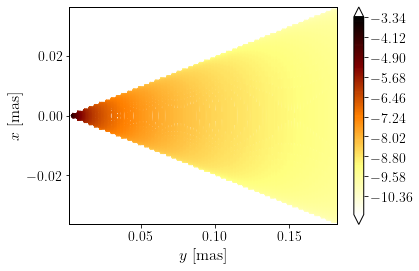

In [20]:
plt.clf()
fig, ax = plt.subplots()
ax.set_xlabel(r"$y$ [mas]")
ax.set_ylabel(r"$x$ [mas]")
cmap  = plt.cm.afmhot_r
#cmap.set_label(r"$S_\nu$ [mJy]")
CS = ax.contour( y_map, x_map, np.log10(F_map), cmap=cmap, levels=512, extend="both")
fig.colorbar( CS)

#### Convolved flux map:

<ipython-input-21-c1a897d76a59>:7: RuntimeWarning: divide by zero encountered in log10
  CS_conv = ax.contour( y_c, x_c, np.log10(F_map_c), cmap=cmap, levels=1024, extend="both")


<Figure size 432x288 with 0 Axes>

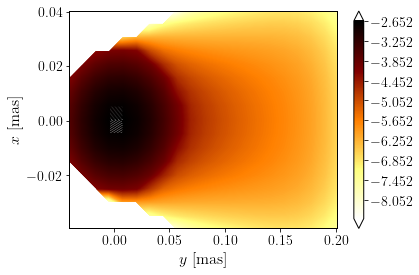

In [21]:
plt.clf()
fig, ax = plt.subplots()
ax.set_xlabel(r"$y$ [mas]")
ax.set_ylabel(r"$x$ [mas]")
cmap  = plt.cm.afmhot_r
#cmap.set_label(r"$S_\nu$ [mJy beam$^{-1}$]")
CS_conv = ax.contour( y_c, x_c, np.log10(F_map_c), cmap=cmap, levels=1024, extend="both")

#Agregar contornos negros a (1, 1.4, 2, 2.8...)*3 mJy beam⁻1.

fig.colorbar( CS_conv)